In [1]:
import pandas as pd
import numpy as np
import pylab as plt
import glob
import matplotlib as mpl
import matplotlib.pyplot as plt



In [2]:
PFILES=glob.glob('../*parquet')
pf_dict={i.split('/')[-1].replace('.parquet','').replace('PREDICTIONS_AFSTD',''):pd.read_csv(i)\
         .groupby('months').median().reset_index()\
         .drop('patient_id',axis=1)\
         .set_index('months') 
         for i in PFILES}
df = pd.concat(
    [v.add_suffix(f"_{k}") for k, v in pf_dict.items()],
    axis=1
)

<Axes: xlabel='months'>

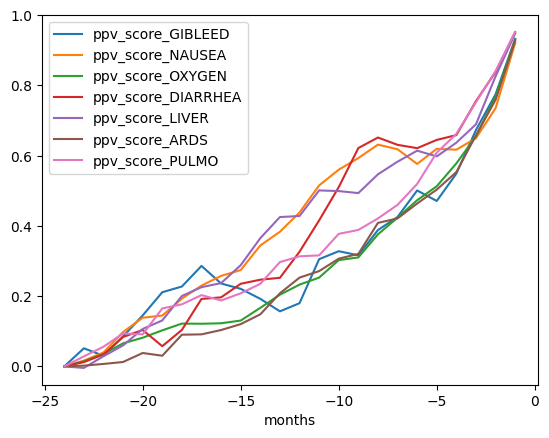

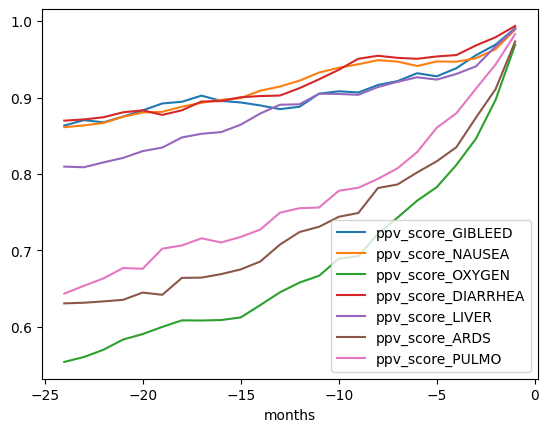

In [3]:
dfn=(df-df.loc[-24,:])
dfn=dfn/dfn.loc[-1,:]
dfnx=df/df.loc[-1,:]
ppvcols=[x for x in dfn.columns if 'ppv' in x]
dfn[ppvcols].ewm(alpha=.7).mean().plot()
dfnx[ppvcols].ewm(alpha=.7).mean().plot()    

In [4]:
ppvcols

['ppv_score_GIBLEED',
 'ppv_score_NAUSEA',
 'ppv_score_OXYGEN',
 'ppv_score_DIARRHEA',
 'ppv_score_LIVER',
 'ppv_score_ARDS',
 'ppv_score_PULMO']

In [5]:
import glob
from math import sqrt

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Load and aggregate prediction files
# ------------------------------------------------------------
PFILES = glob.glob("../*parquet")

pf_dict = {
    i.split("/")[-1]
        .replace(".parquet", "")
        .replace("PREDICTIONS_AFSTD", ""):
        pd.read_csv(i)
        .groupby("months").median()
        .reset_index()
        .drop("patient_id", axis=1)
        .set_index("months")
    for i in PFILES
}

df = pd.concat(
    [v.add_suffix(f"_{k}") for k, v in pf_dict.items()],
    axis=1
)


# ------------------------------------------------------------
# 2. Normalize curves
# ------------------------------------------------------------
dfn = (df - df.loc[-24, :])
dfn = dfn / dfn.loc[-1, :]

dfnx = df / df.loc[-1, :]

ppvcols = [c for c in dfnx.columns if "ppv" in c]


# ------------------------------------------------------------
# 3. Define Npos per event
# ------------------------------------------------------------
# Example:
# Npos_map = {
#     "ppv_score_ARDS": 14000,
#     "ppv_score_OXYGEN": 16000,
#     "ppv_score_PULMO": 12000,
# }

In [6]:
Npos_map = {
        'ppv_score_PULMO': 25986,
    'ppv_score_OXYGEN': 18369,
    'ppv_score_ARDS': 14066,
    'ppv_score_LIVER': 22572,
    'ppv_score_NAUSEA': 61884,
    'ppv_score_GIBLEED': 3410,
    'ppv_score_DIARRHEA': 49092,
}

In [7]:
# ------------------------------------------------------------
# 4. Build single DataFrame with CI columns
# ------------------------------------------------------------
def build_curve_with_ci(curve_df, npos_map, z=1.96):
    """
    Construct a single table containing normalized PPV curves
    and their binomial confidence intervals.

    CI model:
        Var(p) = p (1 - p) / n
    """
    print(curve_df.columns)
    out = pd.DataFrame(index=curve_df.index)

    for col in curve_df.columns:

        if col not in npos_map:
            raise KeyError(f"Missing Npos for column: {col}")

        n = float(npos_map[col])

        p = curve_df[col].astype(float)

        se = np.sqrt(np.maximum(p * (1.0 - p) / n, 0.0))

        lo = np.clip(p - z * se, 0.0, 1.0)
        hi = np.clip(p + z * se, 0.0, 1.0)

        out[col] = p
        out[col + "_lower"] = lo
        out[col + "_upper"] = hi

    return out


# ------------------------------------------------------------
# 5. Generate table
# ------------------------------------------------------------
dfnx_ppv = dfnx[ppvcols]

df_with_ci = build_curve_with_ci(
    curve_df=dfnx_ppv,
    npos_map=Npos_map,
    z=1.96
)

df_with_ci = df_with_ci.reset_index()


# ------------------------------------------------------------
# 6. Write single CSV
# ------------------------------------------------------------
OUTPUT_FILE = "normalized_ppv_curves_with_ci.csv"

df_with_ci.to_csv(
    OUTPUT_FILE,
    index=False,
    float_format="%.6f"
)

print("Wrote:", OUTPUT_FILE)

Index(['ppv_score_GIBLEED', 'ppv_score_NAUSEA', 'ppv_score_OXYGEN',
       'ppv_score_DIARRHEA', 'ppv_score_LIVER', 'ppv_score_ARDS',
       'ppv_score_PULMO'],
      dtype='object')
Wrote: normalized_ppv_curves_with_ci.csv


In [8]:
! cat normalized_ppv_curves_with_ci.csv

months,ppv_score_GIBLEED,ppv_score_GIBLEED_lower,ppv_score_GIBLEED_upper,ppv_score_NAUSEA,ppv_score_NAUSEA_lower,ppv_score_NAUSEA_upper,ppv_score_OXYGEN,ppv_score_OXYGEN_lower,ppv_score_OXYGEN_upper,ppv_score_DIARRHEA,ppv_score_DIARRHEA_lower,ppv_score_DIARRHEA_upper,ppv_score_LIVER,ppv_score_LIVER_lower,ppv_score_LIVER_upper,ppv_score_ARDS,ppv_score_ARDS_lower,ppv_score_ARDS_upper,ppv_score_PULMO,ppv_score_PULMO_lower,ppv_score_PULMO_upper
-24,0.863412,0.851885,0.874938,0.861259,0.858535,0.863982,0.554293,0.547105,0.561481,0.869801,0.866824,0.872778,0.809677,0.804556,0.814798,0.630845,0.622870,0.638820,0.643579,0.637755,0.649402
-23,0.872572,0.861380,0.883764,0.864245,0.861546,0.866944,0.562582,0.555408,0.569755,0.871883,0.868926,0.874839,0.808619,0.803487,0.813752,0.631932,0.623962,0.639903,0.656825,0.651053,0.662598
-22,0.866425,0.855006,0.877843,0.868036,0.865370,0.870703,0.573948,0.566796,0.581099,0.875338,0.872416,0.878260,0.817674,0.812636,0.822711,0.634152,0.626192,0.642112,0.6